# H4 — что вызвало аномалию seed 777?

**Один исходный checkpoint:** `best.pt` от **seed 777**. **Две ветви:** оригинальные ROI и те же ROI с настоящим контекстом +32 px. **Четыре fine-tuning seeds**: 42, 123, 777, 2024; 25 дополнительных эпох для каждой ветви. Сравниваем `ΔF1 = Extended − Original`.

**Отличие от проверки «плохой инициализации»:** начальная модель **всегда одна и та же**. Меняется порядок train ROI и stochastic-операции fine-tuning. Различие F1 при разных FT seeds **не свидетельствует о нарушении детерминизма**.

Код не удаляет и не изменяет основной HPO, использует сохранённый `final_training_summary.json` и validation (без test), требует точного сопоставления вырезок с исходными спутниковыми снимками SECOND. Все 8 дообучений имеют изолированные checkpoints и resume по эпохам.

**Запуск:** `Restart Kernel → Run All`. Время: 8 × 25 = **200 дополнительных эпох** на ограниченной выборке до 800 train ROI; это не полный HPO. Тот же 25-эпоховый бюджет, что использовался в H3b.


## 1. Окружение, данные, один фиксированный checkpoint 777


In [1]:
"""Controlled SECOND ROI context experiments (validation only).

H3a: Evaluate the unchanged trained Tiny Siamese with original crops and
      VERIFIED original-image context (+8/+16/+32px), including black-halo control.
H3b: Paired fine-tuning from each original seed checkpoint, using identical
      prepared train/validation ROI IDs and optimisation budget for the original
      crop and +32px real-context crop. No test data or HPO modifications.
"""
from __future__ import annotations

# Strict reproducibility requires a fresh kernel, before any torch import.
import os
import sys
if 'torch' in sys.modules:
    raise RuntimeError('PyTorch already imported. Restart Kernel and Run All before strict deterministic test.')
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'


import copy
import hashlib
import inspect
import json
import random
import re
import sys
from collections import defaultdict
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt

# ========================= CONFIGURATION =========================
PROJECT_ROOT = Path('/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence')
SEARCH_NAME = 'second_oracle_bounded21_e15_25_40_65_bf16_w4_v1'
SEEDS = (777,)  # One fixed pretrained checkpoint
CONTEXT_PX = (0, 8, 16, 32)
H3B_PADDING = 32                # train & evaluate the larger-context arm on this margin
MAX_VAL_ROIS = 600             # None = all validation; same ROI indices in all arms
MAX_TRAIN_ROIS = 800           # None = all train, quick initial controlled test
FINETUNE_EPOCHS = 25            # SAME number of extra epochs per arm and seed
FINETUNE_LR = 1e-4
FINETUNE_BATCH_SIZE = 8        # logical batches, native-size ROI handled individually
FINETUNE_WEIGHT_DECAY = 1e-3
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
USE_BF16 = True
RUN_H3B = True                 # False runs ONLY frozen H3a
ALIGNMENT_MAE_TOLERANCE = 1.0  # verify exact native crop vs two original RGBs
MIN_VAL_MATCHED = 80
MIN_TRAIN_MATCHED = 120
REQUIRE_ALIGNMENT_FRACTION = 0.75
BOOTSTRAP_REPLICATES = 200
RANDOM_STATE = 2026
# ================================================================

# Enforce deterministic kernels or fail; do not silently fall back.
DETERMINISM_PROTOCOL = {
    'version': 1,
    'cublas_workspace_config': os.environ['CUBLAS_WORKSPACE_CONFIG'],
    'cudnn_deterministic': True,
    'cudnn_benchmark': False,
    'tf32': False,
    'deterministic_algorithms': True,
}
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True)
assert torch.are_deterministic_algorithms_enabled()
print('STRICT DETERMINISM:', DETERMINISM_PROTOCOL)

ROOT = PROJECT_ROOT.expanduser().resolve()
sys.path.insert(0, str(ROOT / 'src'))
from satchange.models import TinySiameseChangeClassifier
from satchange.semantic.data import SemanticROIDataset
from satchange.semantic.second import discover_second
from satchange.semantic.training import logical_forward, semantic_loss
from satchange.utils import load_config

SEARCH = ROOT / 'artifacts/hyperparameter_search/semantic/tiny_siamese_second' / SEARCH_NAME
OUT = ROOT / 'artifacts/debug/tiny_second_context_h4_one_ckpt777_v1' / SEARCH_NAME
OUT.mkdir(parents=True, exist_ok=True)


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def sha256(path):
    obj = hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda: f.read(2**20), b''):
            obj.update(b)
    return obj.hexdigest()


def hash_obj(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()


summary_file = SEARCH / 'final_training_summary.json'
protocol_file = SEARCH / 'pipeline_protocol.json'
if not summary_file.is_file() or not protocol_file.is_file():
    raise FileNotFoundError('Missing completed Tiny training search: ' + str(SEARCH))
summary, protocol = read_json(summary_file), read_json(protocol_file)
if not summary.get('complete') or protocol.get('context',{}).get('task') != 'semantic_roi_classification':
    raise RuntimeError('Need a COMPLETE semantic ROI classification training experiment.')
base = protocol['base']
ident_file = SEARCH / 'notebook_bounded21_protocol.json'
ident = read_json(ident_file).get('identity',{}) if ident_file.is_file() else {}
possible = [ident.get('dataset_root'), protocol.get('dataset_root'),
            protocol.get('context',{}).get('dataset_root'),
            base.get('dataset_root')]
possible.extend(r.get('parameters',{}).get('dataset_root') for r in summary.get('results',[]))
paths = set()
for item in possible:
    if not isinstance(item, str) or not item.strip(): continue
    p = Path(item).expanduser()
    if not p.is_absolute(): p = ROOT / p
    if p.is_file() and p.suffix == '.json': paths.add(p.resolve())
if len(paths) != 1:
    raise RuntimeError('Cannot unambiguously resolve training manifest: ' + repr(sorted(map(str,paths))))
MANIFEST = next(iter(paths))
if ident.get('manifest_sha256') and sha256(MANIFEST) != ident['manifest_sha256']:
    raise RuntimeError('Prepared manifest changed since original training.')

config = copy.deepcopy(load_config(ROOT/'configs/tiny_siamese_change_classifier.yaml'))
config.update(copy.deepcopy(base['semantic_config']))
config['dropout'] = base['model_parameters']['dropout']
config.setdefault('training',{}).update({k:copy.deepcopy(base[k]) for k in
    ('batch_size','num_workers','precision','tf32','class_weights') if k in base})
classes = tuple(config['classes'])
K = len(classes)
val_ds = SemanticROIDataset(MANIFEST,'val',config)
train_ds = SemanticROIDataset(MANIFEST,'train',config)
raw_splits = discover_second(ROOT/'data/SECOND')
raw_scenes = [r for members in raw_splits.values() for r in members if isinstance(r,dict)]
raw_by_id = {}
for item in raw_scenes:
    v = str(item.get('sample_id',''))
    for alias in {v,v.split('/')[-1]}:
        if alias: raw_by_id.setdefault(alias,[]).append(item)

print('Model:',classes,'| train:',len(train_ds),'| val:',len(val_ds))
print('Manifest:',MANIFEST,'| original source scenes:',len(raw_scenes))
print('No SECOND test split will be used.')


STRICT DETERMINISM: {'version': 1, 'cublas_workspace_config': ':4096:8', 'cudnn_deterministic': True, 'cudnn_benchmark': False, 'tf32': False, 'deterministic_algorithms': True}
Model: ('non-vegetated ground surface', 'tree', 'low vegetation', 'water', 'buildings', 'playgrounds') | train: 26867 | val: 5904
Manifest: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/data/SECOND_semantic_cache/0590eed622ef37dcdf469c09be6cd5d83186109d499e755590f1177569d7f7fc/rois/prepared.json | original source scenes: 2968
No SECOND test split will be used.


## 2. Точное сопоставление ROI с оригинальными SECOND-снимками


In [2]:
# ------------------ original-scene aligned context ------------------
manifest_doc = read_json(MANIFEST)
records = {}
def visit(obj):
    if isinstance(obj,dict):
        v=obj.get('sample_id')
        if isinstance(v,str): records.setdefault(v,obj)
        for child in obj.values(): visit(child)
    elif isinstance(obj,list):
        for child in obj: visit(child)
visit(manifest_doc)


def source_path(record, keys):
    for k in keys:
        v=record.get(k)
        if v is None: continue
        p=Path(str(v)).expanduser()
        if not p.is_absolute():
            attempts = (ROOT/p, ROOT/'data/SECOND'/p, MANIFEST.parent/p)
            p = next((x for x in attempts if x.is_file()),p)
        if p.is_file(): return p.resolve()
    return None


def find_source(row, sample_id):
    hints=[]
    for parent in (row,row.get('roi',{}),row.get('source',{})):
        if not isinstance(parent,dict): continue
        for key in ('source_sample_id','source_id','source_scene','scene_id',
                    'original_sample_id','source_image_id'):
            val=parent.get(key)
            if isinstance(val,str): hints.append(val)
    # Prefer exact split-aware IDs (e.g. train/00197); train and val may
    # contain the same basename, but they are different source scenes.
    hints.append(sample_id)
    for hint in hints:
        matches=raw_by_id.get(hint,[])
        if len(matches)==1:return matches[0]
    candidates={}
    for hint in [*hints,sample_id.split('/')[-1]]:
        for r in raw_by_id.get(hint.split('/')[-1],[]):
            candidates[str(r.get('sample_id'))]=r
    if len(candidates)==1: return next(iter(candidates.values()))
    return None


def box_candidates(record,h,w):
    vals=[]
    for parent in (record,record.get('roi',{}),record.get('source',{})):
        if not isinstance(parent,dict): continue
        for name in ('bbox_xyxy','crop_xyxy','crop_box','roi_box','bbox','bounds'):
            v=parent.get(name)
            if isinstance(v,(list,tuple)) and len(v)==4:
                try:
                    a,b,c,d=[int(x) for x in v]
                    vals.extend(((a,b,c,d),(b,a,d,c)))
                except (TypeError,ValueError): pass
        for names in (('x0','y0','x1','y1'),('xmin','ymin','xmax','ymax'),
                      ('left','top','right','bottom')):
            if all(k in parent for k in names):
                try: vals.append(tuple(int(parent[k]) for k in names))
                except (ValueError,TypeError): pass
    return list(dict.fromkeys((a,b,c,d) for a,b,c,d in vals if
        a>=0 and b>=0 and c-a==w and d-b==h))


@lru_cache(maxsize=128)
def rgb(path):
    with Image.open(path) as im: return np.array(im.convert('RGB'),dtype=np.uint8)


def sample_rgb_u8(t):
    if not isinstance(t,torch.Tensor) or t.ndim!=3 or t.shape[0]!=3:
        raise ValueError('Expected float RGB [3,H,W] from SemanticROIDataset')
    if not torch.isfinite(t).all() or t.min()<0 or t.max()>1:
        raise ValueError('Non-finite/out-of-range normalized RGB')
    return np.rint(t.detach().cpu().permute(1,2,0).numpy()*255).clip(0,255).astype(np.uint8)


def compare_mae(region, patch):
    if region.shape != patch.shape: return float('inf')
    return float(np.mean(np.abs(region.astype(np.int16)-patch.astype(np.int16))))


def locate_patch(img,patch):
    # Exact source alignment is verified twice (before and after) below.
    import cv2
    if patch.shape[0]>img.shape[0] or patch.shape[1]>img.shape[1]: return []
    gray_full=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    gray_patch=cv2.cvtColor(patch,cv2.COLOR_RGB2GRAY)
    score=cv2.matchTemplate(gray_full,gray_patch,cv2.TM_SQDIFF_NORMED)
    found=[]
    for _ in range(4):
        minimum, _, (x,y), _ = cv2.minMaxLoc(score)
        if not np.isfinite(minimum) or minimum>0.003: break
        found.append((x,y,x+patch.shape[1],y+patch.shape[0]))
        xx0,xx1=max(0,x-3),min(score.shape[1],x+4)
        yy0,yy1=max(0,y-3),min(score.shape[0],y+4)
        score[yy0:yy1,xx0:xx1]=1
    return found


def align_one(ds, index):
    s=ds[int(index)]
    sid=str(s.get('sample_id',index))
    row=records.get(sid,{})
    if not isinstance(row,dict): row={}
    src=find_source(row,sid)
    if not src: return None, 'source scene not identifiable'
    bpath=source_path(src,('im1','before','before_image','before_path','image1'))
    apath=source_path(src,('im2','after','after_image','after_path','image2'))
    if bpath is None or apath is None: return None, 'original im1/im2 unavailable'
    patch_b,patch_a=sample_rgb_u8(s['before']),sample_rgb_u8(s['after'])
    if patch_b.shape != patch_a.shape: return None, 'input before/after shapes disagree'
    full_b,full_a=rgb(str(bpath)),rgb(str(apath))
    if full_b.shape != full_a.shape: return None, 'source before/after dimensions differ'
    h,w=patch_b.shape[:2]
    if full_b.shape[0]<h or full_b.shape[1]<w:return None,'source smaller than ROI'
    positions=box_candidates(row,h,w)
    # If no verified explicit location, find the original crop by exact RGB matching.
    positions+=locate_patch(full_b,patch_b)
    positions=list(dict.fromkeys(positions))
    good=[]
    for x0,y0,x1,y1 in positions:
        if x1>full_b.shape[1] or y1>full_b.shape[0]: continue
        if (compare_mae(full_b[y0:y1,x0:x1],patch_b)<=ALIGNMENT_MAE_TOLERANCE and
            compare_mae(full_a[y0:y1,x0:x1],patch_a)<=ALIGNMENT_MAE_TOLERANCE):
            good.append((x0,y0,x1,y1))
    if len(good)!=1: return None,'cannot uniquely verify BOTH RGB dates (%d candidates)'%len(good)
    return {'index':int(index),'sample_id':sid,'scene_id':str(src.get('sample_id',sid)),
       'source_before':str(bpath),'source_after':str(apath),'box':good[0],
       'shape':(h,w),'before_label':int(s['before_label']),'after_label':int(s['after_label'])}, None


def selected_indices(count, max_count, seed):
    rng=np.random.default_rng(seed)
    n=count if max_count is None else min(count,max_count)
    return np.sort(rng.choice(count,size=n,replace=False)).tolist()


def align_split(ds,ids,description):
    success,fail=[],defaultdict(int)
    for n,index in enumerate(ids,1):
        item,error=align_one(ds,index)
        if item is not None: success.append(item)
        else: fail[error]+=1
        if n%100==0 or n==len(ids): print(description,'alignment',n,'/',len(ids),'matched',len(success))
    report={'split':description,'requested':len(ids),'matched':len(success),
            'fraction':len(success)/max(1,len(ids)),'failures':dict(fail)}
    (OUT/f'alignment_{description}.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print(description,'alignment report:',report)
    limit=MIN_TRAIN_MATCHED if description=='train' else MIN_VAL_MATCHED
    if len(success)<limit or report['fraction']<REQUIRE_ALIGNMENT_FRACTION:
        raise RuntimeError('Not enough VERIFIED original-scene ROI alignments for '+description+
           '. This is NOT a dataset/architecture failure. Need real source metadata / coordinates '
           'from src/satchange/semantic/second.py and data.py. Do not use artificial padding '
           'as substitute for satellite context. Failure counts: '+repr(dict(fail)))
    return success


val_ids=selected_indices(len(val_ds),MAX_VAL_ROIS,RANDOM_STATE)
train_ids=selected_indices(len(train_ds),MAX_TRAIN_ROIS,RANDOM_STATE+1) if RUN_H3B else []
val_meta=align_split(val_ds,val_ids,'val')
train_meta=align_split(train_ds,train_ids,'train') if RUN_H3B else []
if RUN_H3B:
    train_scene_set = {r['scene_id'] for r in train_meta}
    val_scene_set = {r['scene_id'] for r in val_meta}
    scene_overlap = sorted(train_scene_set & val_scene_set)
    print('Train/validation source-scene overlap:',len(scene_overlap),'scenes')
    if scene_overlap:
        print('WARNING: scene-level validation leakage may exist in the original split. '
              'H3b conclusions are exploratory unless split provenance establishes independence.')
    (OUT/'source_scene_overlap.json').write_text(json.dumps({'overlap_count':len(scene_overlap),
         'example_scene_ids':scene_overlap[:20]},indent=2),encoding='utf-8')


@lru_cache(maxsize=4096)
def cached_mask(split,index):
    dataset = val_ds if split=='val' else train_ds
    return dataset[int(index)]['mask'].detach().cpu().numpy().copy()


def generate_roi(meta, pad, black_halo=False):
    x0,y0,x1,y1=meta['box']
    fb,fa=rgb(meta['source_before']),rgb(meta['source_after'])
    H,W=fb.shape[:2]
    xx0=max(0,x0-pad);yy0=max(0,y0-pad)
    xx1=min(W,x1+pad);yy1=min(H,y1+pad)
    b=fb[yy0:yy1,xx0:xx1].copy()
    a=fa[yy0:yy1,xx0:xx1].copy()
    if black_halo:
        b[:]=0;a[:]=0
        b[y0-yy0:y1-yy0,x0-xx0:x1-xx0]=fb[y0:y1,x0:x1]
        a[y0-yy0:y1-yy0,x0-xx0:x1-xx0]=fa[y0:y1,x0:x1]
    orig_mask=cached_mask(meta.get('_split','val'),meta['index'])
    if orig_mask.shape!=(1,y1-y0,x1-x0): raise RuntimeError('Sample mask mismatch')
    mask=np.zeros((1,yy1-yy0,xx1-xx0),dtype=np.float32)
    mask[:,y0-yy0:y1-yy0,x0-xx0:x1-xx0]=orig_mask
    if not mask.any():raise RuntimeError('Empty changed support')
    return {'before':torch.from_numpy(b.copy()).permute(2,0,1).float().div_(255),
            'after':torch.from_numpy(a.copy()).permute(2,0,1).float().div_(255),
            'mask':torch.from_numpy(mask),
            'before_label':meta['before_label'],'after_label':meta['after_label']}

# Check pads preserve original RGB and masks bit for bit (up to original quantisation).
for m in val_meta[:min(5,len(val_meta))]:
    ref=val_ds[m['index']]
    built=generate_roi(m,0)
    if not torch.equal(ref['mask'].float(),built['mask']):raise RuntimeError('Mask reconstruction changed baseline')
    if (ref['before']-built['before']).abs().max().item()>1/255+1e-6:
        raise RuntimeError('RGB reconstruction differs from the original dataset')


val alignment 100 / 600 matched 100
val alignment 200 / 600 matched 200
val alignment 300 / 600 matched 300
val alignment 400 / 600 matched 400
val alignment 500 / 600 matched 500
val alignment 600 / 600 matched 600
val alignment report: {'split': 'val', 'requested': 600, 'matched': 600, 'fraction': 1.0, 'failures': {}}
train alignment 100 / 800 matched 100
train alignment 200 / 800 matched 200
train alignment 300 / 800 matched 300
train alignment 400 / 800 matched 400
train alignment 500 / 800 matched 500
train alignment 600 / 800 matched 600
train alignment 700 / 800 matched 700
train alignment 800 / 800 matched 800
train alignment report: {'split': 'train', 'requested': 800, 'matched': 800, 'fraction': 1.0, 'failures': {}}
Train/validation source-scene overlap: 0 scenes


## 3. Модель и корректное вычисление семантического Macro F1


In [3]:
# ------------------------- metrics -------------------------
def metric_of(truth_b,truth_a,pred_b,pred_a):
    def calc(true,pred):
        t=np.asarray(true,dtype=np.int64)
        p=np.asarray(pred,dtype=np.int64)
        mat=np.zeros((K,K),dtype=np.int64)
        np.add.at(mat,(t,p),1)
        TP=np.diag(mat);FP=mat.sum(0)-TP;FN=mat.sum(1)-TP
        f=np.divide(2*TP,2*TP+FP+FN,out=np.zeros(K,dtype=float),where=(2*TP+FP+FN)>0)
        return f
    fb,fa=calc(truth_b,pred_b),calc(truth_a,pred_a)
    return {'macro_F1_before':float(fb.mean()),'macro_F1_after':float(fa.mean()),
            'mean_macro_F1':float((fb.mean()+fa.mean())/2),
            'joint_accuracy':float(np.mean((np.asarray(truth_b)==pred_b)&(np.asarray(truth_a)==pred_a))),
            'F1_water_before':float(fb[classes.index('water')]) if 'water' in classes else np.nan,
            'F1_water_after':float(fa[classes.index('water')]) if 'water' in classes else np.nan}


def normalize_key(k):
    for pre in ('module.','_orig_mod.','model.','network.'):
        while k.startswith(pre): k=k[len(pre):]
    return k


def search_weights(obj,needed,depth=0):
    if depth>5:return None
    if isinstance(obj,torch.nn.Module):obj=obj.state_dict()
    if isinstance(obj,dict):
        tensors={normalize_key(k):v for k,v in obj.items() if isinstance(k,str) and torch.is_tensor(v)}
        if needed.issubset(tensors): return {key:tensors[key] for key in needed}
        for k in ('model_state_dict','model_state','state_dict','model','weights','best_weights',
                  'best_model_state_dict','best_state_dict','model_weights','network','checkpoint'):
            if k in obj:
                res=search_weights(obj[k],needed,depth+1)
                if res is not None:return res
        for v in obj.values():
            if isinstance(v,(dict,torch.nn.Module)):
                res=search_weights(v,needed,depth+1)
                if res is not None:return res
    return None


def load_original(seed):
    cp=summary['best_checkpoints']
    path=cp.get(str(seed),cp.get(seed))
    if path is None: raise KeyError('Original final checkpoint for seed '+str(seed)+' not found')
    path=Path(path).expanduser().resolve()
    records=summary.get('results',[])
    opts=next((r.get('parameters',{}) for r in records if
        int(r.get('parameters',{}).get('seed',-1))==seed),{})
    model=TinySiameseChangeClassifier(classes,dropout=opts.get('model_parameters',{}).get('dropout',config['dropout']))
    # Only trusted checkpoints produced by user's own training system.
    payload=torch.load(path,map_location='cpu',weights_only=False)
    weights=search_weights(payload,set(model.state_dict()))
    if weights is None:raise RuntimeError('Could not identify model weights in '+str(path))
    model.load_state_dict(weights,strict=True)
    model.to(DEVICE)
    return model,path


models={}
checkpoint_paths={}
for seed in SEEDS:
    model,path=load_original(seed)
    models[seed]=model
    checkpoint_paths[seed]=path
print('Checkpoints:',{s:str(p) for s,p in checkpoint_paths.items()})


def predict_model(model,items,pad,black_halo=False):
    model.eval()
    bs,as_=[],[]
    with torch.inference_mode():
        for n,item in enumerate(items,1):
            sample=generate_roi(item,pad,black_halo)
            with torch.autocast('cuda',dtype=torch.bfloat16,enabled=(DEVICE.startswith('cuda') and USE_BF16)):
                out=model(sample['before'].unsqueeze(0).to(DEVICE),
                          sample['after'].unsqueeze(0).to(DEVICE),
                          sample['mask'].unsqueeze(0).to(DEVICE))
            bs.append(int(out['before_logits'].argmax(dim=1).item()))
            as_.append(int(out['after_logits'].argmax(dim=1).item()))
            if n%200==0:print('  prediction',n,'/',len(items),'pad',pad)
    return np.asarray(bs,dtype=np.int64),np.asarray(as_,dtype=np.int64)


def score_predictions(seed,stage,variant,items,model,pad,black_halo=False):
    pb,pa=predict_model(model,items,pad,black_halo)
    yb=np.array([r['before_label'] for r in items]); ya=np.array([r['after_label'] for r in items])
    score=metric_of(yb,ya,pb,pa)
    score.update({'seed':seed,'stage':stage,'variant':variant,'context_px':pad,'n':len(items)})
    return score,{'yb':yb,'ya':ya,'pb':pb,'pa':pa}


Checkpoints: {777: '/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hyperparameter_search/semantic/tiny_siamese_second/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1/runs/30d7db14df04a9044efd/tiny_siamese_change_classifier/seed_777/best.pt'}


## 4. Loss и подготовка одинаковых обучающих ROI


In [4]:
# ------------------------- H3b fine-tuning -----------------------
# Recover original optional class weights when the existing semantic_loss
# supports them. Never silently run unweighted CE after weighted training.
loss_weights=base.get('class_weights',None)
loss_kw={}
if loss_weights is not None:
    if isinstance(loss_weights,dict):
        if set(loss_weights)==set(classes):
            loss_weights=[loss_weights[name] for name in classes]
        elif set(loss_weights)==set(map(str,range(K))):
            loss_weights=[loss_weights[str(i)] for i in range(K)]
        else:
            raise RuntimeError('Class weights are mapping with unsupported names: '+str(loss_weights))
    if not isinstance(loss_weights,(list,tuple)) or len(loss_weights)!=K:
        raise RuntimeError('Original class_weights are nonnumeric or dynamically computed: '
            'inspect semantic/training.py before fair H3b fine-tuning.')
    loss_weights=torch.as_tensor(loss_weights,dtype=torch.float32,device=DEVICE)
    keys=inspect.signature(semantic_loss).parameters
    if 'class_weights' in keys: loss_kw={'class_weights':loss_weights}
    elif 'weights' in keys:loss_kw={'weights':loss_weights}
    else:raise RuntimeError('Existing semantic_loss does not accept original nonempty class_weights.')

# Fixed initial model checkpoint per seed, same ROI indices and epochs in both arms.
# This is a LIGHTWEIGHT FINE-TUNING test of H3b, NOT retraining from scratch.

def set_seed(seed):
    random.seed(seed);np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)


def prepare_examples(meta,split,pad):
    return [generate_roi({**item,'_split':split},pad) for item in meta]


## 5. Один checkpoint, разные fine-tuning seeds: 25 эпох Original vs Extended


In [5]:
# ============================================================
# H4: Fixed checkpoint 777 × 4 independent fine-tuning seeds
# Original ROI vs real context +32px, 25 epochs, 800 train ROIs
# ============================================================
from datetime import datetime, timezone

INITIAL_CHECKPOINT_SEED = 777
FT_SEEDS = (42, 123, 777, 2024)
FT_PADDING = 32
assert tuple(SEEDS) == (INITIAL_CHECKPOINT_SEED,)
assert len(FT_SEEDS) == len(set(FT_SEEDS)) == 4
assert H3B_PADDING == FT_PADDING
assert FINETUNE_EPOCHS == 25, 'Fixed preregistered 25-epoch budget'
assert train_meta and val_meta, 'Need verified original-scene ROI alignments.'

# Reuse exactly the SAME aligned training examples for every repeat.
# The only source of variation across fine-tuning repeats is FT seed.
train_original = prepare_examples(train_meta, 'train', 0)
train_extended = prepare_examples(train_meta, 'train', FT_PADDING)
assert len(train_original) == len(train_extended) == len(train_meta)
assert len(val_meta) >= MIN_VAL_MATCHED
assert len(train_meta) >= MIN_TRAIN_MATCHED

# Baseline is a common reference (fixed checkpoint; not trained again).
score0, _ = score_predictions(INITIAL_CHECKPOINT_SEED, 'initial', 'original',
                              val_meta, models[INITIAL_CHECKPOINT_SEED], 0)
print('Fixed starting checkpoint:', checkpoint_paths[INITIAL_CHECKPOINT_SEED])
print('Fixed checkpoint SHA256:', sha256(checkpoint_paths[INITIAL_CHECKPOINT_SEED]))
print('Original baseline F1:', round(score0['mean_macro_F1'], 5))
print('Prepared train/val ROI:', len(train_meta), len(val_meta))
print('Fine-tuning seeds:', FT_SEEDS)
print('Total assignments:', len(FT_SEEDS)*2, '; extra epochs each:', FINETUNE_EPOCHS)

# Resume must use same checkpoint, exact verified ROI identities & training settings.
common_signature = {
    'initial_checkpoint_sha256': sha256(checkpoint_paths[INITIAL_CHECKPOINT_SEED]),
    'manifest_sha256': sha256(MANIFEST),
    'train_ids': [x['sample_id'] for x in train_meta],
    'val_ids': [x['sample_id'] for x in val_meta],
    'epochs': FINETUNE_EPOCHS,
    'learning_rate': FINETUNE_LR,
    'weight_decay': FINETUNE_WEIGHT_DECAY,
    'batch_size': FINETUNE_BATCH_SIZE,
    'precision': 'bf16' if (DEVICE.startswith('cuda') and USE_BF16) else 'fp32',
    'torch_version': str(torch.__version__),
    'determinism': DETERMINISM_PROTOCOL,
    'classes': classes,
}

def run_repeat(ft_seed, arm, pad, examples):
    assert arm in ('original', 'extended')
    assert pad == (0 if arm == 'original' else FT_PADDING)
    fp = hash_obj({**common_signature, 'fine_tune_seed': ft_seed,
                   'arm': arm, 'pad': pad})
    checkpoint_file = OUT/f'h4_fixed777_ft{ft_seed}_{arm}_last.pt'
    model = copy.deepcopy(models[INITIAL_CHECKPOINT_SEED]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=FINETUNE_LR, weight_decay=FINETUNE_WEIGHT_DECAY)
    completed = 0
    set_seed(ft_seed + 1234)
    if checkpoint_file.is_file():
        state = torch.load(checkpoint_file, map_location='cpu', weights_only=False)
        if state['fingerprint'] != fp:
            raise RuntimeError(f'Incompatible H4 checkpoint: {checkpoint_file}')
        model.load_state_dict(state['model_state'], strict=True)
        optimizer.load_state_dict(state['optimizer_state'])
        for opts in optimizer.state.values():
            for name, value in opts.items():
                if torch.is_tensor(value): opts[name] = value.to(DEVICE)
        random.setstate(state['rng_python'])
        np.random.set_state(state['rng_numpy'])
        torch.set_rng_state(state['rng_cpu'])
        if DEVICE.startswith('cuda') and state.get('rng_cuda') is not None:
            torch.cuda.set_rng_state(state['rng_cuda'], device=DEVICE)
        completed = int(state['completed_epoch'])
        if completed > FINETUNE_EPOCHS: raise RuntimeError('Saved epoch exceeds target')
        print(f'RESUME checkpoint777 ft_seed={ft_seed} {arm}: {completed} -> {FINETUNE_EPOCHS}')

    for epoch in range(completed, FINETUNE_EPOCHS):
        model.train()
        # Same shuffle across BOTH arms for this ft_seed and epoch.
        order = np.random.default_rng(ft_seed + 10_000 * epoch).permutation(len(examples))
        losses = []
        for offset in range(0, len(order), FINETUNE_BATCH_SIZE):
            batch = [examples[int(i)] for i in order[offset:offset + FINETUNE_BATCH_SIZE]]
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.bfloat16,
                                enabled=(DEVICE.startswith('cuda') and USE_BF16)):
                outputs, y_before, y_after = logical_forward(model, batch, torch.device(DEVICE))
                loss, _ = semantic_loss(outputs, y_before, y_after, **loss_kw)
            if not bool(torch.isfinite(loss)):
                raise RuntimeError(f'Nonfinite loss ft_seed={ft_seed} {arm} epoch={epoch+1}')
            loss.backward()
            optimizer.step()
            losses.append(float(loss.detach().item()))
        payload = {
            'fingerprint': fp, 'completed_epoch': epoch + 1,
            'model_state': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            'optimizer_state': optimizer.state_dict(),
            'rng_python': random.getstate(), 'rng_numpy': np.random.get_state(),
            'rng_cpu': torch.get_rng_state(),
            'rng_cuda': torch.cuda.get_rng_state(device=DEVICE) if DEVICE.startswith('cuda') else None,
        }
        temp = checkpoint_file.with_suffix('.tmp')
        torch.save(payload, temp)
        temp.replace(checkpoint_file)
        print(f'FT seed={ft_seed} {arm}: epoch {epoch+1}/{FINETUNE_EPOCHS} '
              f'loss={np.mean(losses):.5f}', flush=True)
    model.eval()
    return model

# Save per-seed score immediately; safe to restart after an interruption.
score_file = OUT / 'h4_one_ckpt777_scores_by_ft_seed.csv'
rows = []
for ft_seed in FT_SEEDS:
    pair = {}
    for arm, margin, examples in (
        ('original', 0, train_original),
        ('extended', FT_PADDING, train_extended),
    ):
        tuned = run_repeat(ft_seed, arm, margin, examples)
        result, preds = score_predictions(
            INITIAL_CHECKPOINT_SEED, 'H4', arm, val_meta, tuned, margin
        )
        pair[arm] = (result, preds)
        print(f'Checkpoint 777 | FT seed {ft_seed} | {arm} F1={result["mean_macro_F1"]:.5f}')
        del tuned
        if DEVICE.startswith('cuda'): torch.cuda.empty_cache()

    a, ap = pair['original']; b, bp = pair['extended']
    ci = None
    # Cluster bootstrap implemented locally to avoid relying on H3a execution.
    scenes = [x['scene_id'] for x in val_meta]
    scene_groups = defaultdict(list)
    for i, scene in enumerate(scenes): scene_groups[scene].append(i)
    scene_ids = list(scene_groups)
    rng = np.random.default_rng(RANDOM_STATE + ft_seed)
    delta_boot = []
    for k in range(BOOTSTRAP_REPLICATES):
        sampled = rng.integers(0, len(scene_ids), len(scene_ids))
        ix = np.asarray([j for i in sampled for j in scene_groups[scene_ids[i]]], dtype=int)
        def score_subset(p):
            return metric_of(p['yb'][ix], p['ya'][ix], p['pb'][ix], p['pa'][ix])['mean_macro_F1']
        delta_boot.append(score_subset(bp) - score_subset(ap))
    ci = np.percentile(delta_boot, [2.5, 97.5])

    rows.append({
        'initial_checkpoint_seed': INITIAL_CHECKPOINT_SEED,
        'fine_tune_seed': ft_seed,
        'F1_start_original': score0['mean_macro_F1'],
        'F1_control': a['mean_macro_F1'], 'F1_extended': b['mean_macro_F1'],
        'delta_F1': b['mean_macro_F1'] - a['mean_macro_F1'],
        'before_F1_control': a['macro_F1_before'], 'before_F1_extended': b['macro_F1_before'],
        'after_F1_control': a['macro_F1_after'], 'after_F1_extended': b['macro_F1_after'],
        'joint_accuracy_control': a['joint_accuracy'],
        'joint_accuracy_extended': b['joint_accuracy'],
        'CI95_delta_low': float(ci[0]), 'CI95_delta_high': float(ci[1]),
        'n_train': len(train_meta), 'n_val': len(val_meta),
    })
    df = pd.DataFrame(rows).sort_values('fine_tune_seed')
    df.to_csv(score_file, index=False)
    print('\nCURRENT H4 F1 TABLE')
    display(df[['fine_tune_seed', 'F1_control', 'F1_extended', 'delta_F1',
                'CI95_delta_low', 'CI95_delta_high']].round(5))

print('H4 FINISHED; report:', score_file)


  prediction 200 / 600 pad 0
  prediction 400 / 600 pad 0
  prediction 600 / 600 pad 0
Fixed starting checkpoint: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hyperparameter_search/semantic/tiny_siamese_second/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1/runs/30d7db14df04a9044efd/tiny_siamese_change_classifier/seed_777/best.pt
Fixed checkpoint SHA256: 78edbbe693c9504ffe9df642d97e1b449245e7cb279c42db06a955c73caefc51
Original baseline F1: 0.44619
Prepared train/val ROI: 800 600
Fine-tuning seeds: (42, 123, 777, 2024)
Total assignments: 8 ; extra epochs each: 25
FT seed=42 original: epoch 1/25 loss=1.30617
FT seed=42 original: epoch 2/25 loss=1.23700
FT seed=42 original: epoch 3/25 loss=1.19545
FT seed=42 original: epoch 4/25 loss=1.16067
FT seed=42 original: epoch 5/25 loss=1.13012
FT seed=42 original: epoch 6/25 loss=1.10517
FT seed=42 original: epoch 7/25 loss=1.08130
FT seed=42 original: epoch 8/25 loss=1.05888
FT seed=42 original: epoch 9/25 lo

,fine_tune_seed,F1_control,F1_extended,delta_F1,CI95_delta_low,CI95_delta_high
0,42,0.47014,0.42865,-0.04149,-0.07084,-0.00957


FT seed=123 original: epoch 1/25 loss=1.30498
FT seed=123 original: epoch 2/25 loss=1.23775
FT seed=123 original: epoch 3/25 loss=1.19489
FT seed=123 original: epoch 4/25 loss=1.16035
FT seed=123 original: epoch 5/25 loss=1.13273
FT seed=123 original: epoch 6/25 loss=1.10587
FT seed=123 original: epoch 7/25 loss=1.08231
FT seed=123 original: epoch 8/25 loss=1.05930
FT seed=123 original: epoch 9/25 loss=1.03798
FT seed=123 original: epoch 10/25 loss=1.01816
FT seed=123 original: epoch 11/25 loss=0.99951
FT seed=123 original: epoch 12/25 loss=0.98198
FT seed=123 original: epoch 13/25 loss=0.96463
FT seed=123 original: epoch 14/25 loss=0.94712
FT seed=123 original: epoch 15/25 loss=0.93200
FT seed=123 original: epoch 16/25 loss=0.91500
FT seed=123 original: epoch 17/25 loss=0.89881
FT seed=123 original: epoch 18/25 loss=0.88513
FT seed=123 original: epoch 19/25 loss=0.87099
FT seed=123 original: epoch 20/25 loss=0.85691
FT seed=123 original: epoch 21/25 loss=0.84322
FT seed=123 original: 

,fine_tune_seed,F1_control,F1_extended,delta_F1,CI95_delta_low,CI95_delta_high
0,42,0.47014,0.42865,-0.04149,-0.07084,-0.00957
1,123,0.44909,0.44403,-0.00506,-0.02675,0.01892


FT seed=777 original: epoch 1/25 loss=1.30730
FT seed=777 original: epoch 2/25 loss=1.23884
FT seed=777 original: epoch 3/25 loss=1.19637
FT seed=777 original: epoch 4/25 loss=1.16158
FT seed=777 original: epoch 5/25 loss=1.13259
FT seed=777 original: epoch 6/25 loss=1.10553
FT seed=777 original: epoch 7/25 loss=1.08279
FT seed=777 original: epoch 8/25 loss=1.06002
FT seed=777 original: epoch 9/25 loss=1.03877
FT seed=777 original: epoch 10/25 loss=1.01834
FT seed=777 original: epoch 11/25 loss=1.00037
FT seed=777 original: epoch 12/25 loss=0.98208
FT seed=777 original: epoch 13/25 loss=0.96417
FT seed=777 original: epoch 14/25 loss=0.94628
FT seed=777 original: epoch 15/25 loss=0.93009
FT seed=777 original: epoch 16/25 loss=0.91505
FT seed=777 original: epoch 17/25 loss=0.89920
FT seed=777 original: epoch 18/25 loss=0.88429
FT seed=777 original: epoch 19/25 loss=0.87035
FT seed=777 original: epoch 20/25 loss=0.85648
FT seed=777 original: epoch 21/25 loss=0.84308
FT seed=777 original: 

,fine_tune_seed,F1_control,F1_extended,delta_F1,CI95_delta_low,CI95_delta_high
0,42,0.47014,0.42865,-0.04149,-0.07084,-0.00957
1,123,0.44909,0.44403,-0.00506,-0.02675,0.01892
2,777,0.46747,0.41375,-0.05372,-0.09420,-0.01365


FT seed=2024 original: epoch 1/25 loss=1.30534
FT seed=2024 original: epoch 2/25 loss=1.23719
FT seed=2024 original: epoch 3/25 loss=1.19685
FT seed=2024 original: epoch 4/25 loss=1.16156
FT seed=2024 original: epoch 5/25 loss=1.13185
FT seed=2024 original: epoch 6/25 loss=1.10602
FT seed=2024 original: epoch 7/25 loss=1.08098
FT seed=2024 original: epoch 8/25 loss=1.05920
FT seed=2024 original: epoch 9/25 loss=1.03847
FT seed=2024 original: epoch 10/25 loss=1.01856
FT seed=2024 original: epoch 11/25 loss=0.99991
FT seed=2024 original: epoch 12/25 loss=0.97964
FT seed=2024 original: epoch 13/25 loss=0.96423
FT seed=2024 original: epoch 14/25 loss=0.94707
FT seed=2024 original: epoch 15/25 loss=0.92981
FT seed=2024 original: epoch 16/25 loss=0.91522
FT seed=2024 original: epoch 17/25 loss=0.89887
FT seed=2024 original: epoch 18/25 loss=0.88385
FT seed=2024 original: epoch 19/25 loss=0.86929
FT seed=2024 original: epoch 20/25 loss=0.85532
FT seed=2024 original: epoch 21/25 loss=0.84256
F

,fine_tune_seed,F1_control,F1_extended,delta_F1,CI95_delta_low,CI95_delta_high
0,42,0.47014,0.42865,-0.04149,-0.07084,-0.00957
1,123,0.44909,0.44403,-0.00506,-0.02675,0.01892
2,777,0.46747,0.41375,-0.05372,-0.09420,-0.01365
3,2024,0.44734,0.43711,-0.01023,-0.03272,0.00457


H4 FINISHED; report: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/debug/tiny_second_context_h4_one_ckpt777_v1/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1/h4_one_ckpt777_scores_by_ft_seed.csv


## 6. Таблица F1 по каждому fine-tuning seed и среднее



=== FIXED CHECKPOINT 777 — PAIRED F1 RESULTS ===


,fine_tune_seed,F1_start_original,F1_control,F1_extended,delta_F1,CI95_delta_low,CI95_delta_high
0,42,0.44619,0.47014,0.42865,-0.04149,-0.07084,-0.00957
1,123,0.44619,0.44909,0.44403,-0.00506,-0.02675,0.01892
2,777,0.44619,0.46747,0.41375,-0.05372,-0.09420,-0.01365
3,2024,0.44619,0.44734,0.43711,-0.01023,-0.03272,0.00457



mean Delta F1: -0.02762
sample_std(Delta F1): 0.0237
Extended wins: 0 of 4
Control mean/std F1: 0.45851 0.01196
Extended mean/std F1: 0.43089 0.01304


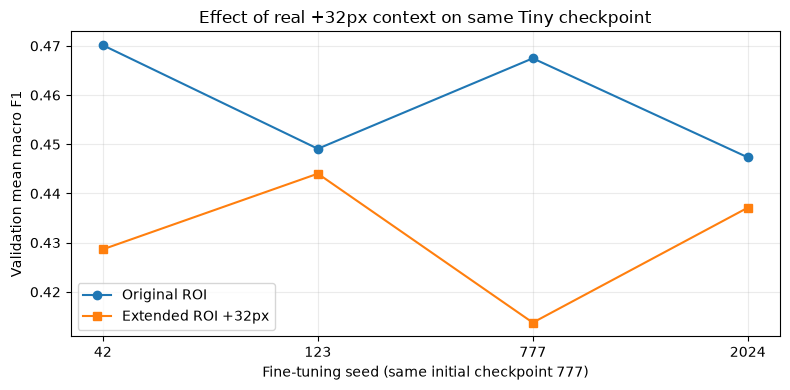


Interpretation: this checks SENSITIVITY TO FINETUNING SEED for ONE
initial checkpoint, not initial-weight quality across pretrained seeds.
No test split has been evaluated. Do not overinterpret n=4 repeats.


In [6]:
# ============================================================
# H4 — PRIMARY INTERPRETATION TABLE (results only)
# ============================================================
df = pd.read_csv(score_file).sort_values('fine_tune_seed')
assert len(df) == len(FT_SEEDS) and set(df.fine_tune_seed) == set(FT_SEEDS)

print('\n=== FIXED CHECKPOINT 777 — PAIRED F1 RESULTS ===')
display(df[['fine_tune_seed', 'F1_start_original', 'F1_control', 'F1_extended',
            'delta_F1', 'CI95_delta_low', 'CI95_delta_high']].round(5))
print('\nmean Delta F1:', round(df.delta_F1.mean(), 5))
print('sample_std(Delta F1):', round(df.delta_F1.std(ddof=1), 5))
print('Extended wins:', int((df.delta_F1>0).sum()), 'of', len(df))
print('Control mean/std F1:', round(df.F1_control.mean(), 5),
      round(df.F1_control.std(ddof=1), 5))
print('Extended mean/std F1:', round(df.F1_extended.mean(), 5),
      round(df.F1_extended.std(ddof=1), 5))

fig, ax = plt.subplots(figsize=(8,4))
x = np.arange(len(df))
ax.plot(x, df.F1_control.values, '-o', label='Original ROI')
ax.plot(x, df.F1_extended.values, '-s', label='Extended ROI +32px')
ax.set_xticks(x, [str(int(x)) for x in df.fine_tune_seed.values])
ax.set_xlabel('Fine-tuning seed (same initial checkpoint 777)')
ax.set_ylabel('Validation mean macro F1')
ax.set_title('Effect of real +32px context on same Tiny checkpoint')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT/'h4_one_ckpt777_per_seed.png', dpi=150)
plt.show()
plt.close(fig)

print('\nInterpretation: this checks SENSITIVITY TO FINETUNING SEED for ONE')
print('initial checkpoint, not initial-weight quality across pretrained seeds.')
print('No test split has been evaluated. Do not overinterpret n=4 repeats.')
